<a href="https://colab.research.google.com/github/24cs123/DL-unit-test/blob/main/SMS_Spam_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [ ]:
print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)


All libraries imported successfully!
TensorFlow version: 2.21.0


In [ ]:

from google.colab import files

uploaded = files.upload()


Saving archive.zip to archive (1).zip


In [ ]:
import os
import zipfile

In [ ]:
csv_files = [f for f in uploaded.keys() if f.lower().endswith(".csv")]

In [ ]:
if not csv_files:
    zip_files = [f for f in uploaded.keys() if f.lower().endswith(".zip")]

In [ ]:
if zip_files:
        with zipfile.ZipFile(zip_files[0], "r") as z:
            z.extractall("/content/sms_dataset")

In [ ]:
for root, dirs, filenames in os.walk("/content/sms_dataset"):
            csv_files.extend(
                os.path.join(root, f)
                for f in filenames
                if f.lower().endswith(".csv")
            )

In [ ]:
if not csv_files:
    raise ValueError("No CSV file found. Upload the dataset CSV or ZIP.")


In [ ]:
df = pd.read_csv(csv_files[0], encoding="latin-1")

In [ ]:
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())
print("Column names:", df.columns.tolist())


Dataset loaded successfully!
Dataset shape: (5572, 2)
     v1                                                 v2
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
Column names: ['v1', 'v2']


In [ ]:

# Select the correct label and message columns
df = df[["v1", "v2"]].copy()
df.columns = ["label", "message"]

# Remove missing values and duplicate messages
df = df.dropna(subset=["label", "message"])
df = df.drop_duplicates(subset=["message"])

# Keep only valid labels
df["label"] = df["label"].astype(str).str.strip().str.lower()
df = df[df["label"].isin(["ham", "spam"])]

# Convert labels into numbers: ham = 0, spam = 1
df["label"] = df["label"].map({"ham": 0, "spam": 1})

print("Cleaned dataset shape:", df.shape)
print("\nLabel counts:")
print(df["label"].value_counts())

df.head()


Cleaned dataset shape: (5169, 2)

Label counts:
label
0    4516
1     653
Name: count, dtype: int64


,label,message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " URL ", text)
    text = re.sub(r"\S+@\S+", " EMAIL ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["message"] = df["message"].apply(clean_text)

print(df[["label", "message"]].head())


   label                                            message
0      0  go until jurong point crazy available only in ...
1      0                            ok lar joking wif u oni
2      1  free entry in 2 a wkly comp to win fa cup fina...
3      0        u dun say so early hor u c already then say
4      0  nah i don t think he goes to usf he lives arou...


In [ ]:

X = df["message"].values
y = df["label"].values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))


Training messages: 4135
Testing messages: 1034


In [ ]:

tokenizer = Tokenizer(num_words=5000, oov_token="<OOV>")

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

print("Original message:")
print(X_train[0])

print("\nTokenized message:")
print(X_train_seq[0])


Original message:
cool so how come you havent been wined and dined before

Tokenized message:
[276, 26, 45, 66, 3, 461, 113, 3384, 8, 3385, 184]


In [ ]:

max_length = 100

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("Training shape:", X_train_pad.shape)
print("Testing shape:", X_test_pad.shape)


Training shape: (4135, 100)
Testing shape: (1034, 100)


In [ ]:

vocab_size = min(5000, len(tokenizer.word_index) + 1)

model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=32,
        mask_zero=True
    ),
    LSTM(32),
    Dropout(0.3),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:

history = model.fit(
    X_train_pad,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)


Epoch 1/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 14s 71ms/step - accuracy: 0.8942 - loss: 0.3592 - val_accuracy: 0.9444 - val_loss: 0.1856
Epoch 2/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 8s 52ms/step - accuracy: 0.9791 - loss: 0.0833 - val_accuracy: 0.9686 - val_loss: 0.1003
Epoch 3/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 7s 65ms/step - accuracy: 0.9940 - loss: 0.0308 - val_accuracy: 0.9867 - val_loss: 0.0654
Epoch 4/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 5s 52ms/step - accuracy: 0.9964 - loss: 0.0174 - val_accuracy: 0.9819 - val_loss: 0.0766
Epoch 5/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 6s 59ms/step - accuracy: 0.9991 - loss: 0.0057 - val_accuracy: 0.9758 - val_loss: 0.1005
Epoch 6/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 6s 60ms/step - accuracy: 0.9991 - loss: 0.0035 - val_accuracy: 0.9819 - val_loss: 0.1035
Epoch 7/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 6s 58ms/step - accuracy: 0.9997 - loss: 0.0018 - val_accuracy: 0.9807 - val_loss: 0.1078
Epoch 8/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 10s 52ms/step - accuracy: 1.0000 - loss: 9.6996e-04 - va

In [ ]:

y_probability = model.predict(X_test_pad).ravel()

y_pred = (y_probability >= 0.5).astype(int)

print("Actual labels:   ", y_test[:10])
print("Predicted labels:", y_pred[:10])


33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
Actual labels:    [0 0 0 0 0 0 0 0 0 0]
Predicted labels: [0 0 0 0 0 0 0 0 0 0]


In [ ]:

print("MODEL EVALUATION")

print("Accuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("Precision:",
      round(precision_score(y_test, y_pred, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, y_pred, zero_division=0), 4))

print("F1-score:",
      round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Ham", "Spam"],
    zero_division=0
))


MODEL EVALUATION
Accuracy: 0.9826
Precision: 0.9669
Recall: 0.8931
F1-score: 0.9286

Classification Report:
              precision    recall  f1-score   support

         Ham       0.98      1.00      0.99       903
        Spam       0.97      0.89      0.93       131

    accuracy                           0.98      1034
   macro avg       0.98      0.94      0.96      1034
weighted avg       0.98      0.98      0.98      1034



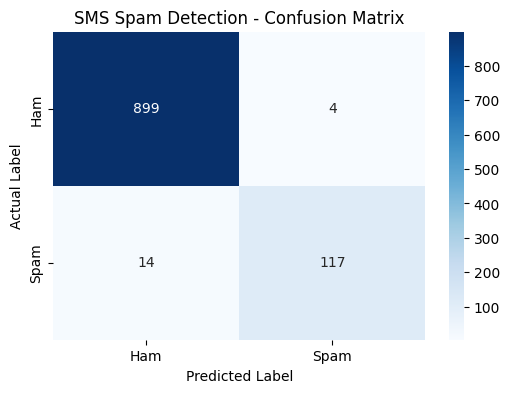

In [ ]:

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SMS Spam Detection - Confusion Matrix")
plt.show()


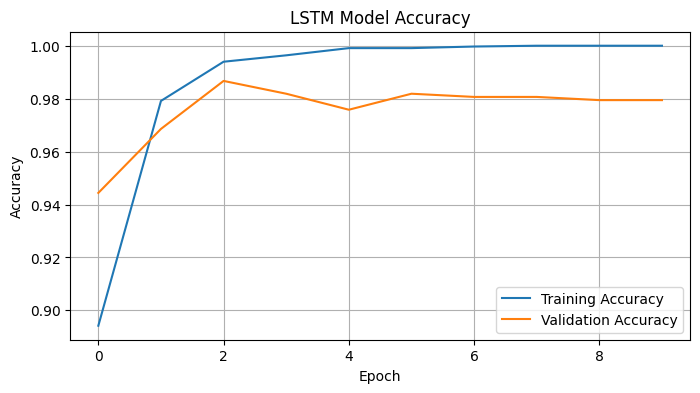

In [ ]:

plt.figure(figsize=(8, 4))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Model Accuracy")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:

def predict_sms(message):
    cleaned = clean_text(message)

    sequence = tokenizer.texts_to_sequences([cleaned])

    padded = pad_sequences(
        sequence,
        maxlen=max_length,
        padding="post",
        truncating="post"
    )

    probability = float(
        model.predict(padded, verbose=0)[0][0]
    )

    if probability >= 0.5:
        result = "SPAM"
    else:
        result = "HAM (NOT SPAM)"

    print("\nMessage:", message)
    print("Prediction:", result)
    print("Spam score:", round(probability, 4))


predict_sms("Congratulations! You won a free prize. Call now!")

predict_sms("Hi, are we meeting at college tomorrow?")

predict_sms("URGENT! Claim your cash reward now!")



Message: Congratulations! You won a free prize. Call now!
Prediction: SPAM
Spam score: 0.9959

Message: Hi, are we meeting at college tomorrow?
Prediction: HAM (NOT SPAM)
Spam score: 0.0

Message: URGENT! Claim your cash reward now!
Prediction: SPAM
Spam score: 0.9993


In [ ]:

model.save("/content/sms_spam_lstm.keras")

print("Model saved successfully!")


Model saved successfully!


In [ ]:

from google.colab import files

files.download("/content/sms_spam_lstm.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>